In [1]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.oneDwellfunctions import *
from EDAspy.optimization import UMDAc
from EGPA import *
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [2]:
#####  E S T I M A T I O N      O F     G A U S S I A N     P R O C E S S    A L G O R I T H M #########################
##################### done in the simplest way with a loop #############################################################

# from sklearn.gaussian_process import GaussianProcessRegressor
# from sklearn.gaussian_process.kernels import RBF
# from oneDwellfunctions import *
# import numpy as np
# from utils import _parallel_apply_along_axis
# import matplotlib.pyplot as plt
# import warnings
# warnings.filterwarnings("ignore")

# ## Prueba resolver pozo potencial infinito con proceso gaussiano.

# #Primero definimos los puntos del grid constante. Caja de lado 5 con 25 puntos.
# #L = 5 #Esto ahora va como argumento dentro de la definición de las funciones
# n_variables = 25

# #Parámetros algoritmo, iteraciones totales, individuos por generación, seleccionados, num elites
# N_it = 200
# inds = 1000
# inds_sel = 21
# num_elites = 1

# X_grid = np.linspace(start=0, stop=L, num=n_variables).reshape(-1,1) #para que sean 25 filas y 1 columna

# #ARRAY para guardar todos los individuos generados
# sampleados = np.empty((N_it, inds, n_variables+1)) #la columna extra será el fitness

# #Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
# #Los datos que conocemos son las amplitudes en x=0 x=5 que son 0
# X_train = X_grid[[0,-1]]
# Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array

# #Definimos el Kernel inicial. Y ajustamos los datos obervados.
# kernel = 0.01 * RBF(length_scale=0.5, length_scale_bounds=(0.2, 5))
# gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
# gaussian_process.fit(X_train, Y_train)

# #Una vez fijadas las evidencias podemos samplear una colección de funciones que van a ser las soluciones iniciales.
# sampled = gaussian_process.sample_y(X_grid, n_samples=inds).T #Las filas representan cada solucion (amplitudes sobre grid fijo), columnas puntos del grid

# #Normalizamos las soluciones, que creo que puede evitar errores ya que las amplitudes si no salen números muy pequeños.
# for ind in range(len(sampled)):
#             integral = 0
#             for var in range(sampled.shape[1]):
#                 integral = integral + (sampled[ind,:][var]**2)*(L/(n_variables-1)) ###Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

#             A = (1/integral)**0.5
#             sampled[ind, :] = A * sampled[ind, :]

# #Ahora evaluamos las soluciones con la función de coste
# evaluations = _parallel_apply_along_axis(oneD_wellExpEexcitated, 1, sampled,  **{'E':0, 'Psi':Psi_fund})

# #Ahora ordenamos las soluciones siendo las primeras las mejores y nos quedamos con inds_sel mejores
# ordering = evaluations.argsort()
# best_indices_truc = ordering[:inds_sel]
# mejores = sampled[best_indices_truc, :]
# #Guardamos todos los individuos, los seleccionados serán los inds_sel primeros
# sampleados[0, :, :] = np.hstack((sampled[ordering, :], np.reshape(evaluations[ordering], (len(evaluations), 1))))

# #Es la primera generación, creamos un array que guardará los élites
# elites = sampled[ordering[:num_elites], :]
# elites_eval = evaluations[ordering[:num_elites]]

# #Vectores para guardar las medias en cada punto del grid y su error
# pm_means = []
# pm_stds = []

# for _ in range(N_it):
    
#     # for i in range(len(mejores)):
#     #     plt.plot(X_grid, mejores[i,:])#, label='Sol. EGPA')
   
#     # plt.legend();

#     #De estos mejores individuos aprendemos la media y varianza de las amplitudes en cada punto del grid
#     pm = np.zeros((2, n_variables)) #La primera fila serán las medias, la segunda la std. Las columnas por tanto son media std de cada punto del grid
#     for i in range(n_variables):
#                 pm[0, i] = np.mean(mejores[:, i])
#                 pm[1, i] = np.std(mejores[:, i])

#     #Fijamos las evidencias y condiciones de contorno
#     pm[0, [0,-1]] = 0
#     pm[1,[0,-1]] = 0

#     pm_means.append(pm[0,:])
#     pm_stds.append(pm[1, :])

#     #Ahora tenemos que actulizar el kernel, pasando como ruido a cada punto del grid estas std y como evidencias la media de amplitudes de las mejores sols
#     #Definimos el Kernel inicial. Y ajustamos los datos obervados.
#     kernel = 0.01* RBF(length_scale=0.5, length_scale_bounds=(0.2, 5))
#     gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9, alpha=pm[1,:]**2)
#     gaussian_process.fit(X_grid, pm[0, :])

#     #Una vez fijadas las evidencias podemos samplear de nuevo a ver si hemos aprendido algo
#     sampled = gaussian_process.sample_y(X_grid, n_samples=inds).T #Las filas representan cada solucion (amplitudes sobre grid fijo), columnas puntos del grid
#     #Normalizamos las soluciones, que creo que puede evitar errores ya que las amplitudes si no salen números muy pequeños.
#     for ind in range(len(sampled)):
#                 integral = 0
#                 for var in range(sampled.shape[1]):
#                     integral = integral + (sampled[ind,:][var]**2)*(L/(n_variables-1)) ###Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

#                 A = (1/integral)**0.5
#                 sampled[ind, :] = A * sampled[ind, :]

#     #Ahora evaluamos las soluciones con la función de coste
#     #A partir de la iteración 10 usamos la definición de la función de coste exponencial, que es más precisa
#     if _ >= 5:
#            evaluations = _parallel_apply_along_axis(oneD_wellExpEexcitated, 1, sampled, **{'E':E_guess, 'Psi':Psi_fund, 'exponential': True})
#     else:
#            evaluations = _parallel_apply_along_axis(oneD_wellExpEexcitated, 1, sampled, **{'E':E_guess, 'Psi':Psi_fund})

#     #Ahora pegamos a las evaluaciones e individuos los élites y ordenamos
#     evaluations = np.concatenate((evaluations, elites_eval))
#     sampled = np.concatenate((sampled, elites))
#     ordering = evaluations.argsort()
#     best_indices_truc = ordering[:inds_sel]
#     mejores = sampled[best_indices_truc, :]

#     sampleados[_, :, :] = np.hstack((sampled[ordering[:inds], :], np.reshape(evaluations[ordering[:inds]], (len(evaluations[ordering[:inds]]), 1))))
#     #Guardando sampleados así, no estamos guardando los num_elites peores de cada generación

#     elites = sampled[ordering[:num_elites], :]
#     elites = np.tile(elites, (11,1))
#     elites_eval = evaluations[ordering[:num_elites]]
#     elites_eval = np.tile(elites_eval, (11))

#     # import matplotlib.pyplot as plt
#     # for i in range(len(mejores)):
#     #     plt.plot(X_grid, mejores[i,:])


In [3]:
# class EGPAResult:

#     """
#     Object used to encapsulate the result and information of the EDA during the execution
#     """

#     def __init__(self,
#                  best_ind: np.array,
#                  best_cost: float,
#                  n_fev: int,
#                  best_sampled: np.array,
#                  data: np.array,
#                  means: list,
#                  stds: list,
#                  GP_hist: list,
#                  cpu_time: float):

#         """

#         :param best_ind: Best result found in the execution.
#         :param best_cost: Cost of the best result found.
#         :param n_fev: Number of cost function evaluations.
#         :param best_sampled: 3D array (gen, bestsampled ind, variables+fitness)
#         :param data: 3D array (gen, sorted with fitness inds, variables+fitness) with all generated individuals
#         :param means: list of lists with means in each grid position in a given iteration
#         :param stds: list of lists with stds in each grid position in a given iteration
#         :param GP_hist: list with Gaussian Process object from each generation
#         :param cpu_time: CPU time invested in the optimization.
#         """

#         self.best_ind = best_ind
#         self.best_cost = best_cost
#         self.n_fev = n_fev
#         self.best_sampled = best_sampled
#         self.data = data
#         self.means = means
#         self.std = stds
#         self.GP_hist = GP_hist
#         self.cpu_time = cpu_time

#     def __str__(self):
#         string = "\tNFVALS = " + str(self.n_fev) + " F = " + str(self.best_cost) + "CPU time (s) = " + \
#                  str(self.cpu_time)
#         return string

In [4]:
# ## ESTIMATION OF GAUSSIAN PROCESS ALGORITHM ##

# import numpy as np
# from scipy.stats import norm
# from sklearn.gaussian_process import GaussianProcessRegressor
# from sklearn.gaussian_process.kernels import RBF
# from time import process_time
# import copy

# class EGPA():

#     """
#     This class implements the Estimation of Gaussian Process Algortihm. The goal is to obtain a gaussian process where the mean corresponds with
#     some specific points observations f(x) that are refined iteratively. For a fixed set of grid points Gaussian Process is started (with optional initial
#     observations). Functions are sampled from the GP (for fixed grid points x and observations f(x)) and the best ones, according to a optimization function,
#     are selected. The mean and std of f(x) at each observation point x is calculated from selected functions and this is used to fit a new Gaussian Process
#     with these evidences with noise at each grid point. 
#     """
#     def __init__(self,
#                  size_gen: int,
#                  grid_X: np.array,
#                  max_iter: int,
#                  dead_iter: int,
#                  alpha: float = 0.5,
#                  elite_factor: float = 0.4,
#                  init_kernels: int = 10,
#                  disp: bool = True,
#                  parallelize: bool = False,
#                  init_data: tuple = None ):


#         # super().__init__(size_gen=size_gen, grid_X=grid_X ,max_iter=max_iter, dead_iter=dead_iter, #n_variables=n_variables,
#         #                  alpha=alpha, elite_factor=elite_factor, disp=disp, parallelize=parallelize,
#         #                  init_data=init_data)
#         """
#         :param size_gen: Number of functions to be sampled from GP in each iteration
#         :param grid_X: array of shape (#of_grid_points, 1) with x fixed values
#         :param max_iter: Number of max iterations of EGPA
#         :param dead_iter: Number of max iterations without improvment after which algorithm will stop
#         :param n_variables: Number of variables i.e. fixed grid points
#         :param alpha: Proportion (respect to total size_gen solutions) of solutions to be used to re-learn and updated fit GP
#         :param elite_factor: Proportion (respect to total size_gen solutions) of best-ever found solutions that must be used to compare and truncate solutions
#         :param init_kernels: Number of different RBF kernels to initialize population
#         :param disp: boolean to choose whether the algorithm run info should be displayed or not when minimize
#         :param init_data: tuple of tuples with initial known observations or constraints 
#                ((grid points x ), (observations f(x))) = ((x_1, x_2, ..., x_m), (f(x_1), f(x_2), ..., f(x_m)))
#                both arrays must be shape ((n, 1)) where n=grid points. Observations must coincide with some of the points defined in the grid_X
#         """

#         self.size_gen = size_gen
#         self.grid_X = grid_X
#         self.max_iter = max_iter
#         self.dead_iter = dead_iter
#         self.alpha = alpha
#         self.elite_factor = elite_factor
#         self.init_kernels = init_kernels
#         self.disp = disp
#         self.parallelize = parallelize
#         self.init_data = init_data

#         self.truncation_length = int(size_gen * alpha)
#         self.elite_length = int(size_gen * elite_factor)
#         self.iteration = 1

#         self.n_variables = grid_X.shape[0]
#         self.grid_size = grid_X[-1,0] - grid_X[-2, 0]
#         self.problem_size = grid_X[-1,0] - grid_X[0,0]
#         # self.evaluations = np.array(0)
#         # self.evaluations_elite = np.array(0)

#         self.generation = None
#         self.elite_temp = None
#         self.pm = np.zeros((2, self.n_variables))

#         #Vectores, lista de listas, para guardar las medias en cada punto del grid y su error
#         self.pm_means = [] 
#         self.pm_stds = []

#         #self.data = np.empty((1, size_gen, self.n_variables+1)) #la columna extra será el fitness

#         ########### K E R N E L   del  PROCESO GAUSSIANO ################################
#         self.lower_bound = 0.001 #lower bound for std of observations at given point f(x)
#         self.kernel = 0.01 * RBF(length_scale=self.grid_size/np.sqrt(2), length_scale_bounds=(self.grid_size/np.sqrt(2), self.problem_size/2))
#         # self.gaussian_process = GaussianProcessRegressor(kernel=self.kernel, n_restarts_optimizer=9)
#         #################################################################################

#     def _initialize_population(self):
#         '''
#         Creates the initial population from the desired number of distinct RBF kernels. A 'grid search' is performed over the length scale parameter.
#         The minimum value for the length scale is defined depending on the grid size, as lambda = grid_size/sqrt(2). 
#         The maximum value is defined as half the total range of the independent variable.
#         '''
                
#         lengths = np.linspace(self.grid_size/np.sqrt(2), self.problem_size/2, self.init_kernels)
#         samplesperkernel = int(self.size_gen/self.init_kernels)
#         for scale in lengths:
#             kernel = 0.01 * RBF(length_scale=scale,  length_scale_bounds='fixed') #length_scale_bounds=(scale[0], scale[0]))
#             gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
#             gaussian_process.fit(self.init_data[0], self.init_data[1])

#             if scale==lengths[0]:
#                 self.generation=gaussian_process.sample_y(self.grid_X, n_samples=samplesperkernel).T
#             else:
#                 self.generation = np.concatenate([self.generation, gaussian_process.sample_y(self.grid_X, n_samples=samplesperkernel).T])


#     def _sample_new_gen(self):
#         """
#         Samples new functions from the Gaussian Process.
#         :param size: number of samplings from GP.
#         :return: array with the dataset sampled. Fixed x grid points and observations f(x) sampled from GP
#         :rtype: np.array
#         """

#         self.generation = self.gaussian_process.sample_y(self.grid_X, n_samples=self.size_gen).T


#     def _normalize(self, dataset:np.array):
#         '''
#         Normalizes the solutions i.e. multiply by a constant so that the integral of the solution^2 = 1.
#         Be aware that integration depends on problem definition and size!!!!
#         '''
#         #grid_size = L/variables     dx of integral
#         #grid_size = 5/(self.n_variables-1)

#         #Assuming a constant size grid we know grid size independently of problem parameters (better code-wise)
#         #self.grid_size = grid_X[-1,0] - grid_X[-2, 0]

#         for ind in range(len(dataset)):
#                 integral = 0
#                 for var in range(dataset.shape[1]):
#                     integral = integral + (dataset[ind,:][var]**2)*self.grid_size ##Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

#                 A = (1/integral)**0.5
#                 dataset[ind, :] = A * dataset[ind, :]

#     # def _symmetrize(self, dataset:np.array):
#     #     '''
#     #     Symmetrize the solutions. In our problem both f(x) and -f(x) solve the equation and minimize the cost function.
#     #     Como solución provisional a este problema identificamos el signo de las amplitudes en los primeros puntos del grid y las soluciones que no coincidan se multiplican por -1.
#     #     Bastará con hacerlo una generación para los individuos seleccionados.
#     #     '''
#     #     print(f'Función de simetrización it {self.iteration} \n\n', 'Referencia de signo f(x_1) mejor:', dataset[0, 1], '\n')
#     #     for row in range(1, len(dataset)):
#     #         print('Antes de simetrización:', dataset[row, 1])
#     #         if (dataset[0, 1] > 0 and dataset[row, 1] < 0):
#     #             dataset[row, :] = dataset[row, :] * -1 
#     #         if (dataset[0, 1] < 0 and dataset[row, 1] > 0):
#     #             dataset[row, :] = dataset[row, :] * -1
#     #         print('       Después de simetrización:', dataset[row, 1], '\n\n\n')
    

#     def _learn(self, dataset: np.array):
#         """
#         Learns the mean and variances from selected (promising) observations f(x) for given and fixed x grid points. Then updates (re-learns) a new Gaussian
#         Process, with the means f(x) as observed points with corresponding noise (Variances at each f(x)).

#         :param dataset: dataset from which learn the probabilistic model. Will correspond to selected function observations.
#         """
#         for i in range(self.n_variables):
#             self.pm[0, i] = np.mean(dataset[:, i])
#             self.pm[1, i] = np.std(dataset[:, i])

#             if self.pm[1, i] < self.lower_bound:
#                 self.pm[1, i] = self.lower_bound #lower bound of std for observation at given point f(x_i)

#         if self.init_data is not None:
#             #Fijamos las evidencias y condiciones de contorno acorde a las observaciones o condiciones de contorno conocidas
#             for i in range(len(self.init_data[1])):
#                 self.pm[0, np.where(self.grid_X==self.init_data[0][i])[0]] = self.init_data[1][i]
#                 self.pm[1, np.where(self.grid_X==self.init_data[0][i])[0]] = 0

#         self.pm_means.append(self.pm[0,:])
#         self.pm_stds.append(self.pm[1, :])

#         #Ahora tenemos que actulizar el kernel, pasando como ruido a cada punto del grid estas std y como evidencias la media de amplitudes de las mejores sols
#         #Definimos el Kernel inicial. Y ajustamos los datos obervados.
#         self.gaussian_process = GaussianProcessRegressor(kernel=self.kernel, n_restarts_optimizer=9, alpha=self.pm[1,:]**2)
#         self.gaussian_process.fit(self.grid_X, self.pm[0,:])


#     def _check_generation_parallel(self, objective_function: callable, params:dict , exp_from:int):

#         if self.iteration >= exp_from:
#             params['exponential'] = True 
#             self.evaluations = _parallel_apply_along_axis(objective_function, 1, self.generation, **params)

#         else:
#             self.evaluations = _parallel_apply_along_axis(objective_function, 1, self.generation, **params)

#         self.iteration += 1

#     def _truncate(self):
#         """ 
#         Selection of the best individuals functions of the actual generation, comparing them against best ever found ones as well.
#         """

#         self.genpluseliteinds = np.concatenate([self.generation, self.elite_temp])
#         self.genpluselitefitness =  np.append(self.evaluations, self.evaluations_elite)


#         # first add the elite selection to be considered
#         self.generation = np.concatenate([self.generation, self.elite_temp])
#         self.evaluations = np.append(self.evaluations, self.evaluations_elite)
        

#         # now we truncate
#         self.ordering = self.evaluations.argsort()
#         best_indices_truc = self.ordering[: self.truncation_length]
#         best_indices_elit = self.ordering[: self.elite_length]
#         self.elite_temp = self.generation[best_indices_elit, :]
#         self.generation = self.generation[best_indices_truc, :]
#         self.evaluations_elite = np.take(self.evaluations, best_indices_elit)
#         self.evaluations = np.take(self.evaluations, best_indices_truc)

#     def minimize(self, cost_function: callable, params: dict, exp_from: int ,output_runtime: bool = True):
#         """
#         Minimize function to execute the EGPA optimization. By default, the optimizer is designed to minimize a cost
#         function; if maximization is desired, just add a minus sign to your cost function.

#         :param cost_function: cost function to be optimized and accepts an array as argument.
#         :param params: dict with **args to be passed to the cost function
#         :exp_from: iteration number from which to use the exponential definition of cost function
#         :param output_runtime: true if information during runtime is desired.
#         :return: EdaResult object with results and information.
#         :rtype: EdaResult
#         """

#         t1 = process_time()
#         not_better = 0

#         ### list to store pm object in each iteration
#         GP_hist = []
#         #####################################################
        
#         for gen in range(0, self.max_iter):

#             # if gen==0 and self.init_data is not None: #Provisional, no sé cuáles son los GP prior si no se pasan observaciones iniciales
#             #     #self.kernel = 0.01 * RBF(length_scale=self.grid_size, length_scale_bounds=(self.grid_size, self.problem_size))
#             #     self.gaussian_process = GaussianProcessRegressor(kernel=self.kernel, n_restarts_optimizer=9)
#             #     self.gaussian_process.fit(self.init_data[0], self.init_data[1])

#             if gen==0:
#                 self._initialize_population()
#             else:
#                 self._sample_new_gen()

#             self._normalize(self.generation)

#             ### 'Corregimos' las soluciones cuyas primeras amplitudes sean negativas.
#             ### de esta manera eliminamos el problema de la simetría de las soluciones.
#             for i in range(len(self.generation)):
#                 if self.generation[i, 2] < 0:
#                     self.generation[i, :] = self.generation[i, :]*-1
            
#             self._check_generation_parallel(cost_function, params, exp_from)

#             best_fitness_local = min(self.evaluations)
            
#             #### Guardar mejor individuo sampleado en un array 3D ###################################
#             best_ind_local = np.where(self.evaluations == best_fitness_local)[0][0]
#             best_ind_local = self.generation[best_ind_local]

#             if gen==0:
#                 self.best_fitness_global = best_fitness_local
#                 self.best_ind_global = best_ind_local

#             bestindplusfitness = np.hstack((best_ind_local, best_fitness_local))
#             bestindplusfitness = np.reshape(bestindplusfitness, (1, bestindplusfitness.shape[0]))
#             bestindplusfitness = np.reshape(bestindplusfitness, (1, bestindplusfitness.shape[0], bestindplusfitness.shape[1]))

#             if gen==0:
#                 ### array to save best sampled individual (gen, variablesfitness)
#                 self.best_sampled = bestindplusfitness

#             if gen > 0:
#                 self.best_sampled = np.vstack((self.best_sampled, bestindplusfitness))
#             #############################################################################


#             if gen==0:
#                 worst = max(self.evaluations)
#                 worst_ind = np.where(self.evaluations == worst)[0][0]
#                 self.elite_temp = np.reshape(self.generation[worst_ind], (1,len(self.generation[worst_ind])))
#                 self.evaluations_elite = worst
                
#             self._truncate()

#             #self._symmetrize(self.generation)
#             #self._symmetrize(self.elite_temp)

#             ########################################################################################################
#             # 3D array (generation, individuals, variables + evaluation) creation
#             # Saving selected individuals only
#             datagen = np.column_stack((self.genpluseliteinds[self.ordering[:self.size_gen], :], self.genpluselitefitness[self.ordering[:self.size_gen]])) #Once truncated we paste only size gen first indiviudals + evaluation
#             ##### This way we are losing information of the last #elitelenght individuals, because we paste to the size_gen individuals the elite individuals we evaluate and sort and are only saving in data the first #size_gen ones
#             if gen==0:
#                 self.data = np.reshape(datagen, (1, datagen.shape[0], datagen.shape[1]))
#             #Guardamos todos los individuos, los seleccionados serán los inds_sel primeros
#             if gen > 0:
#                 self.data = np.vstack((self.data, np.reshape(datagen, (1, datagen.shape[0], datagen.shape[1]))))
#             #########################################################################################################


#             ### Saving Gaussian Process object using deepcopy
#             if gen>0:
#                 pm_temp = copy.deepcopy(self.gaussian_process)
#                 GP_hist.append(pm_temp)

#             self._learn(dataset=self.generation)

#             # update the best values ever
#             if best_fitness_local < self.best_fitness_global: #(< self.best_fitness_global + - tolerancia) se podría añadir
#                 self.best_fitness_global = best_fitness_local
#                 self.best_ind_global = best_ind_local
#                 not_better = 0

#             else:
#                 not_better += 1
#                 if not_better == self.dead_iter:
#                     break

#             if output_runtime:
#                 print('IT: ', gen, '\tBest cost: ', self.best_fitness_global)

#         if self.disp:
#             print("\tNFEVALS = " + str((gen+1) * self.size_gen) + " F = " + str(self.best_fitness_global))
#             print("\tX = " + str(self.best_ind_global))

#         t2 = process_time()

#         ###########################################################
#         ####################Modified by Daniel Conde ##############
#         ##### added best_ind_hist, sel_inds_hist, all_inds_hist, prob_mod_hist, prob_clone_hist to eda_result >>> requires changes in eda_result.py #######
#         egpa_result = EGPAResult(self.best_ind_global, self.best_fitness_global, gen*self.size_gen,
#                                self.best_sampled, self.data, self.pm_means, self.pm_stds ,GP_hist, t2-t1)

#         return egpa_result




In [5]:
L=5
n_variables = 51
X_grid = np.linspace(start=0, stop=L, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 x=5 que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
params = {'L':L}

In [6]:
def Psi_n(n):
    return((2/L)**0.5*np.sin(n*np.pi*np.linspace(0, L, n_variables)/L))

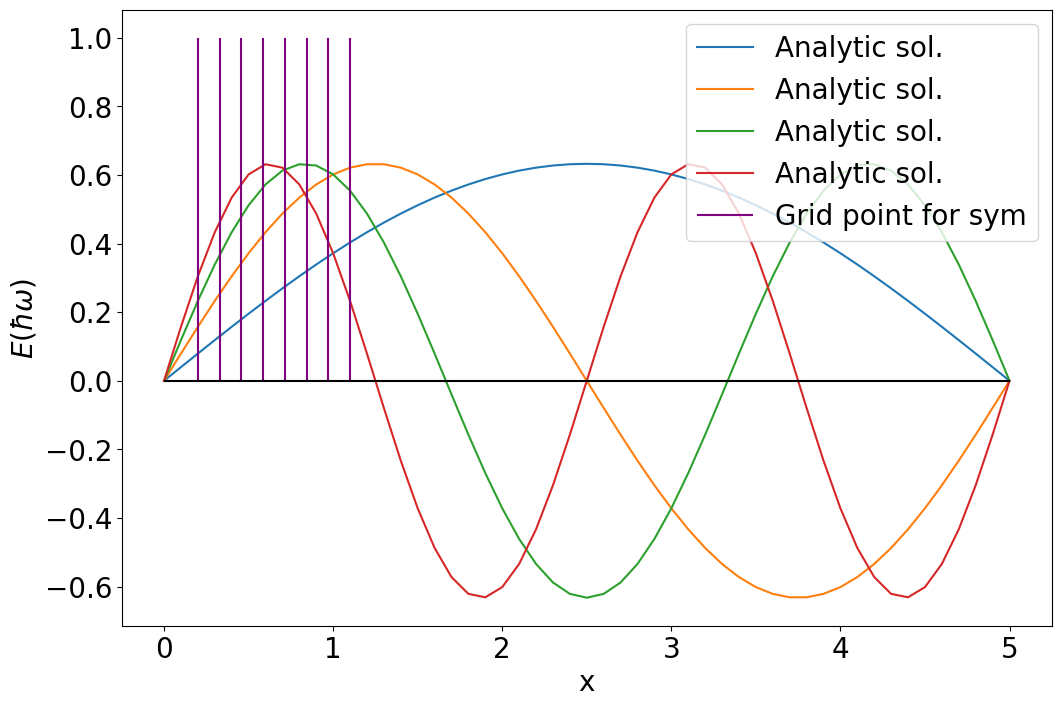

In [ ]:
# #PLOT para ver puntos de SIMTERIZACIÓN
# import matplotlib.pyplot as plt
# plt.figure(figsize=(12, 8))
# plt.rcParams.update({'font.size':20})

# #plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', label=f' $\Psi(x)$', alpha=0.9)
# for i in range(1, 5):
#     plt.plot(X_grid, Psi_n(i), label='Analytic sol.')
   

# #plt.vlines(x=X_grid[[50, 55 , 60, 65]], ymin=0, ymax=1, colors='purple')
# plt.vlines(x=np.linspace(0.2, 1.1, 8), ymin=0, ymax=1, colors='purple', label='Grid point for sym')
# plt.hlines(y=0, xmin=0, xmax=5, colors='k')

# #plt.gca().set_title('Función de onda $\Psi(x)$')
# plt.xlabel('x')
# plt.gca().set_ylabel(r'$E (\hbar \omega)$')
# plt.legend(loc = 'upper right')
# #plt.savefig('Figures/QHObyEGPAbigfont.pdf');

In [7]:
Gaussian = EGPA(size_gen=500, grid_X=X_grid, max_iter=200, dead_iter=20, alpha=0.1, elite_factor=0.05, init_kernels=5 ,parallelize=True, init_data=(X_train, Y_train))
egparesultground = Gaussian.minimize(oneD_wellExpE, params, exp_from = 2, output_runtime=True)

IT:  0 	Best cost:  0.03915542440368248
IT:  1 	Best cost:  -0.961798375774053
IT:  2 	Best cost:  -0.9618068922496215
IT:  3 	Best cost:  -0.9618094169318528
IT:  4 	Best cost:  -0.9618102175759212
IT:  5 	Best cost:  -0.9618102175759212
IT:  6 	Best cost:  -0.9618102175759212
IT:  7 	Best cost:  -0.9618102175759212
IT:  8 	Best cost:  -0.9618102175759212
IT:  9 	Best cost:  -0.9618102175759212
IT:  10 	Best cost:  -0.9618102175759212
IT:  11 	Best cost:  -0.9618102175759212
IT:  12 	Best cost:  -0.9618102175759212
IT:  13 	Best cost:  -0.9618102175759212
IT:  14 	Best cost:  -0.9618102175759212
IT:  15 	Best cost:  -0.9618102175759212
IT:  16 	Best cost:  -0.9618102175759212
IT:  17 	Best cost:  -0.9618102175759212
IT:  18 	Best cost:  -0.9618102175759212
IT:  19 	Best cost:  -0.9618102175759212
IT:  20 	Best cost:  -0.9618102175759212
IT:  21 	Best cost:  -0.9618102175759212
IT:  22 	Best cost:  -0.9618102175759212
IT:  23 	Best cost:  -0.9618102175759212
	NFEVALS = 12500 F = -0.961

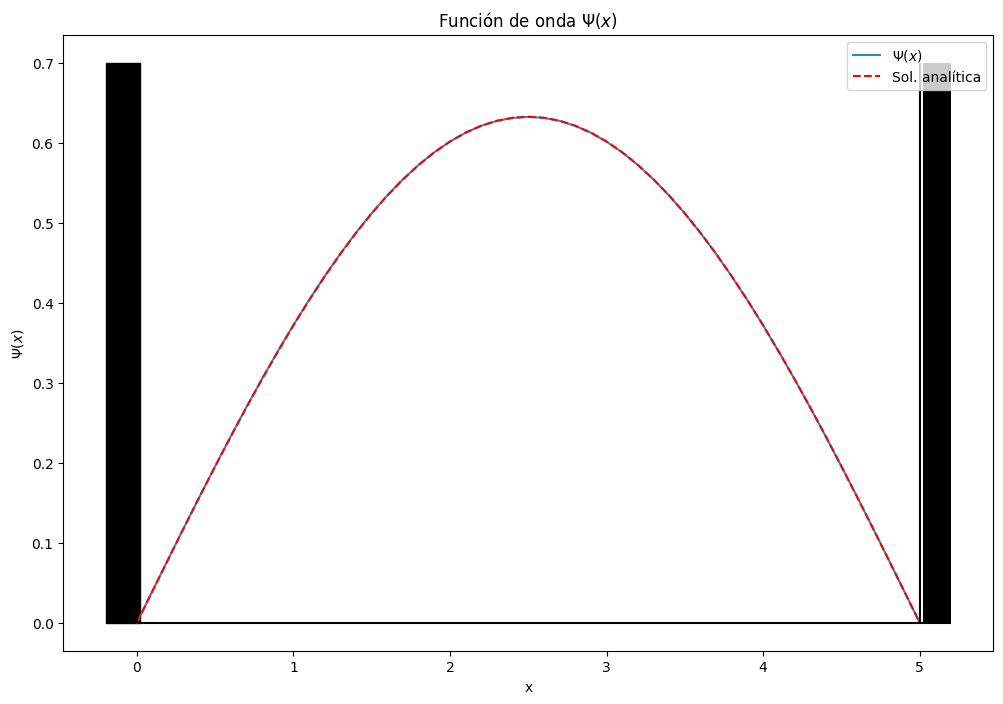

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultground.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'r--', label='Sol. analítica')
plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=X_grid[[50, 55 , 60, 65]], ymin=0, ymax=4.5, colors='purple')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, 0.02, 0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [0, 0.7, 0.7, 0]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [9]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultground.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultground.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'k-', label='Sol. analítica')
    plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
    plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, 0.02, 0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [0, 0.7, 0.7, 0]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=24), Outpu…

In [10]:
Psi_fund=egparesultground.data[-1, 0, :-1]
E_fund = np.sqrt(-np.log(-egparesultground.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E': E_fund, 'Psi': Psi_fund}

In [11]:
np.mean(abs(Psi_n(0)-Psi_fund))

np.float64(0.39464419279637347)

In [12]:
Gaussian = EGPA(size_gen=500, grid_X=X_grid, max_iter=200, dead_iter=50, alpha=0.1, elite_factor=0.05, init_kernels=5,parallelize=True, init_data=(X_train, Y_train))
egparesultexc1 = Gaussian.minimize(oneD_wellExpEexcitated, params, exp_from = 4, output_runtime=True)

IT:  0 	Best cost:  0.3560885144471213
IT:  1 	Best cost:  0.35218338688830153
IT:  2 	Best cost:  0.34965992260525364
IT:  3 	Best cost:  -0.7050030382566281
IT:  4 	Best cost:  -0.7050072507854409
IT:  5 	Best cost:  -0.7050186365736085
IT:  6 	Best cost:  -0.7050186365736085
IT:  7 	Best cost:  -0.7050186365736085
IT:  8 	Best cost:  -0.7050186365736085
IT:  9 	Best cost:  -0.7050186365736085
IT:  10 	Best cost:  -0.7050186365736085
IT:  11 	Best cost:  -0.7050186365736085
IT:  12 	Best cost:  -0.7050218249690059
IT:  13 	Best cost:  -0.7050218249690059
IT:  14 	Best cost:  -0.7050218249690059
IT:  15 	Best cost:  -0.7050218249690059
IT:  16 	Best cost:  -0.7050218249690059
IT:  17 	Best cost:  -0.7050218249690059
IT:  18 	Best cost:  -0.7050218249690059
IT:  19 	Best cost:  -0.7050218249690059
IT:  20 	Best cost:  -0.7050218249690059
IT:  21 	Best cost:  -0.7050218249690059
IT:  22 	Best cost:  -0.7050218249690059
IT:  23 	Best cost:  -0.7050218249690059
IT:  24 	Best cost:  -0.705

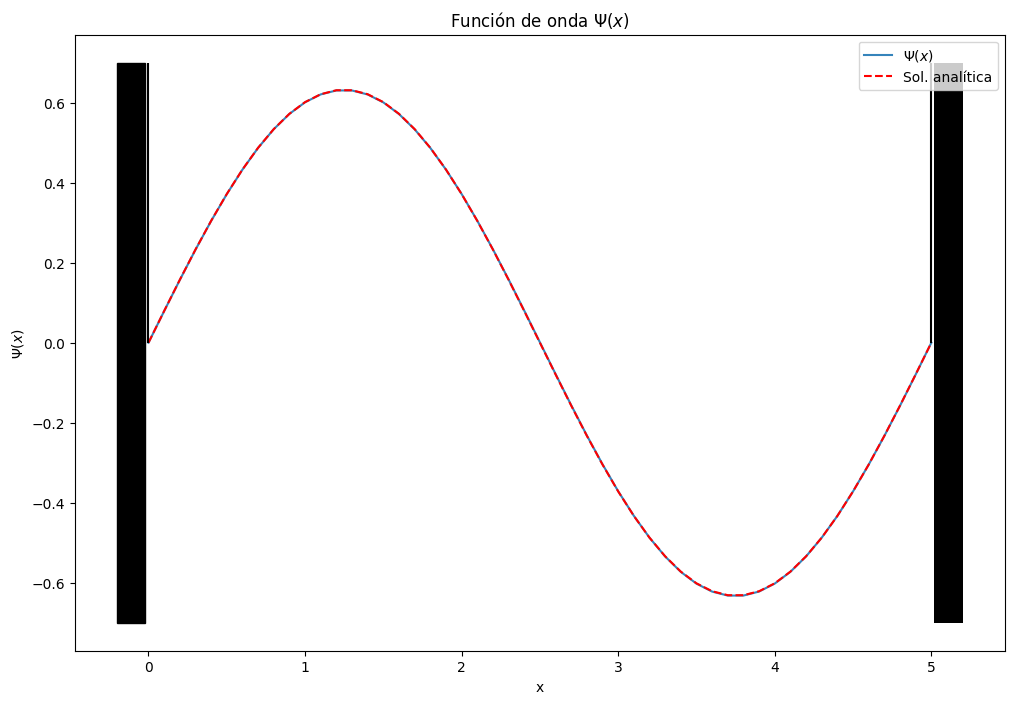

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc1.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(2), 'r--', label='Sol. analítica')
plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=X_grid[[50, 55 , 60, 65]], ymin=0, ymax=4.5, colors='purple')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [14]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(len(egparesultexc1.data)):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc1.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(2), 'k-', label='Sol. analítica')
    plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
    plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultexc1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=88), Outpu…

In [15]:
Psi_1=egparesultexc1.data[-1, 0, :-1]
E1 = np.sqrt(-np.log(-egparesultexc1.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}

In [16]:
Gaussian = EGPA(size_gen=600, grid_X=X_grid, max_iter=600, dead_iter=60, alpha=0.1, elite_factor=0.05, init_kernels=6,parallelize=True, init_data=(X_train, Y_train))
egparesultexc2 = Gaussian.minimize(oneD_wellExpEexcitated3, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  1.3655625215654807
IT:  1 	Best cost:  1.1160130321318062
IT:  2 	Best cost:  0.9796420312745866
IT:  3 	Best cost:  0.973449516840368
IT:  4 	Best cost:  -0.3782964432699743
IT:  5 	Best cost:  -0.37868810160837946
IT:  6 	Best cost:  -0.3793664934615011
IT:  7 	Best cost:  -0.3797725679860951
IT:  8 	Best cost:  -0.3799992729285317
IT:  9 	Best cost:  -0.3801945569820146
IT:  10 	Best cost:  -0.38041386724045795
IT:  11 	Best cost:  -0.3805083743523093
IT:  12 	Best cost:  -0.380609170990885
IT:  13 	Best cost:  -0.3806273734238236
IT:  14 	Best cost:  -0.38065017903308773
IT:  15 	Best cost:  -0.3806630418284017
IT:  16 	Best cost:  -0.3806630418284017
IT:  17 	Best cost:  -0.3806712061799969
IT:  18 	Best cost:  -0.3806712061799969
IT:  19 	Best cost:  -0.3806726656905289
IT:  20 	Best cost:  -0.3806726656905289
IT:  21 	Best cost:  -0.3806726656905289
IT:  22 	Best cost:  -0.3806726656905289
IT:  23 	Best cost:  -0.3806736364143162
IT:  24 	Best cost:  -0.38067

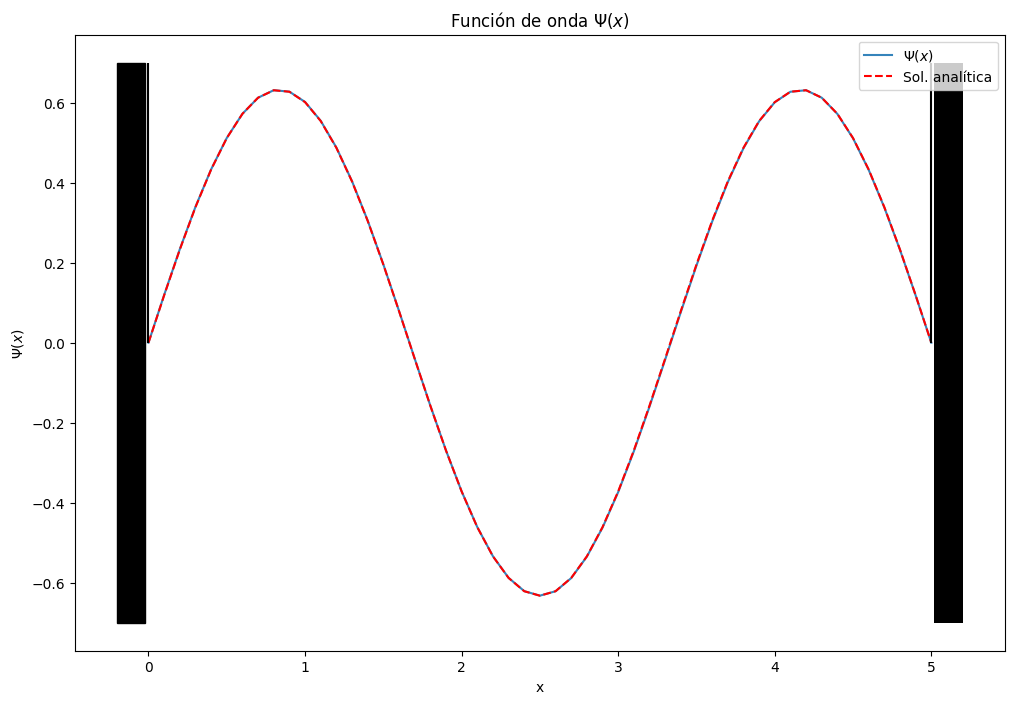

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc2.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(3), 'r--', label='Sol. analítica')
plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=X_grid[[50, 55 , 60, 65]], ymin=0, ymax=4.5, colors='purple')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [18]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultexc2.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc2.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(3), 'k-', label='Sol. analítica')
    plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
    plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultexc2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=96), Outpu…

In [19]:
Psi_2=egparesultexc2.data[-1, 0, :-1]
E2 = np.sqrt(-np.log(-egparesultexc2.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}

In [20]:
Gaussian = EGPA(size_gen=600, grid_X=X_grid, max_iter=600, dead_iter=60, alpha=0.1, elite_factor=0.05, init_kernels=6,parallelize=True, init_data=(X_train, Y_train))
egparesultexc3 = Gaussian.minimize(oneD_wellExpEexcitated4, params, exp_from = 10, output_runtime=True)

IT:  0 	Best cost:  4.3315399379985156
IT:  1 	Best cost:  4.3315399379985156
IT:  2 	Best cost:  4.3315399379985156
IT:  3 	Best cost:  3.0914924556708314
IT:  4 	Best cost:  3.0914924556708314
IT:  5 	Best cost:  3.0914924556708314
IT:  6 	Best cost:  3.0914924556708314
IT:  7 	Best cost:  3.0914924556708314
IT:  8 	Best cost:  3.0914924556708314
IT:  9 	Best cost:  -0.00031868943346546755
IT:  10 	Best cost:  -0.00031868943346546755
IT:  11 	Best cost:  -0.00031868943346546755
IT:  12 	Best cost:  -0.00031868943346546755
IT:  13 	Best cost:  -0.00031868943346546755
IT:  14 	Best cost:  -0.00031868943346546755
IT:  15 	Best cost:  -0.00031868943346546755
IT:  16 	Best cost:  -0.00031868943346546755
IT:  17 	Best cost:  -0.00031868943346546755
IT:  18 	Best cost:  -0.00031868943346546755
IT:  19 	Best cost:  -0.00031868943346546755
IT:  20 	Best cost:  -0.00031868943346546755
IT:  21 	Best cost:  -0.00031868943346546755
IT:  22 	Best cost:  -0.00031868943346546755
IT:  23 	Best cost: 

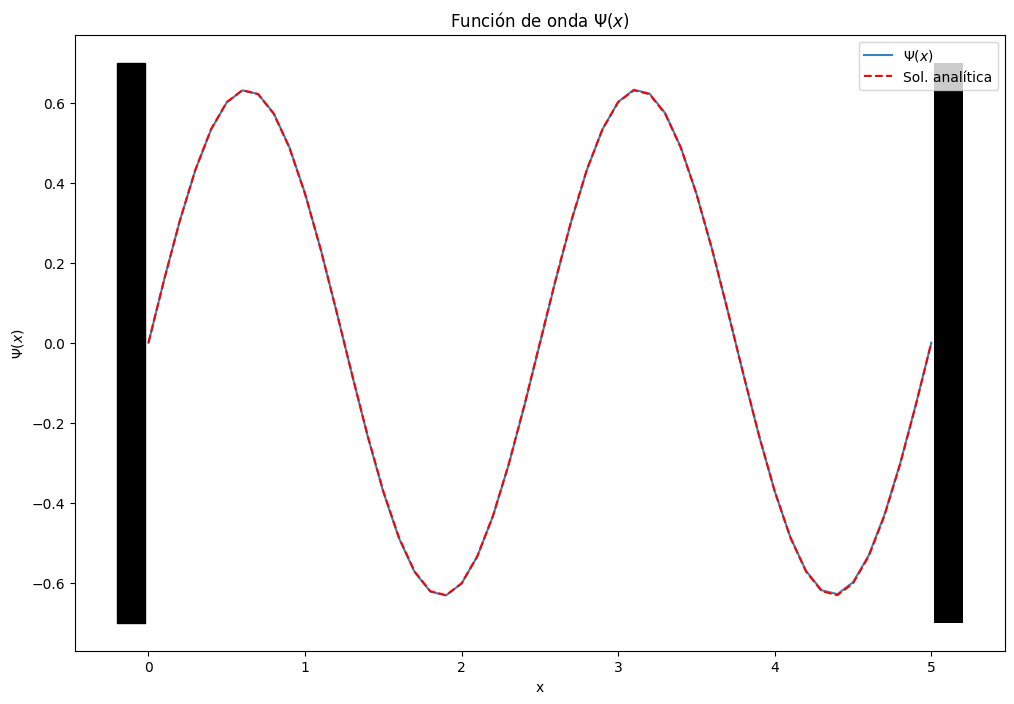

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc3.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(4), 'r--', label='Sol. analítica')
# plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
# plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=X_grid[[50, 55 , 60, 65]], ymin=0, ymax=4.5, colors='purple')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [22]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultexc3.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc3.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(4), 'k-', label='Sol. analítica')
    # plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
    # plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultexc3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=329), Outp…

# **Oscilador armónico cuántico**

In [28]:
from EGPA import *

In [29]:
from oneDwellfunctions import *
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [30]:
from oneDQHarmOscillatorfunctions import *
n_variables = 51
X_grid = np.linspace(start=-4, stop=4, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=-4 (-inf) x=4 (inf) que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
params = {'x':X_grid}

In [31]:
#Analytical solutions definitions

#Ground state
APsi0 = np.exp(-X_grid**2/2)
integral =0
for i in range(len(APsi0)):
    integral = integral + (APsi0[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi0)-1))

B = (1/integral)**0.5
APsi0 = B * APsi0

#1st excitated state
APsi1 = np.exp(-X_grid**2/2)*2*X_grid
integral =0
for i in range(len(APsi1)):
    integral = integral + (APsi1[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi1)-1))

B = (1/integral)**0.5
APsi1 = B * APsi1

#if results_dict['eda_resultExpE1'].sel_inds_hist[-1, 0, :-1][10]>0:
   # APsi1 = -APsi1


#2nd excitated state
APsi2 = np.exp(-X_grid**2/2)*(4*X_grid**2-2)
integral =0
for i in range(len(APsi2)):
    integral = integral + (APsi2[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi2)-1))

B = (1/integral)**0.5
APsi2 = B * APsi2

#if results_dict['eda_resultExpE2'].sel_inds_hist[-1, 0, :-1][3]<0:
   # APsi2=-APsi2

#3rd excitated state
APsi3 = np.exp(-X_grid**2/2)*(8*X_grid**3-12*X_grid)
integral =0
for i in range(len(APsi3)):
    integral = integral + (APsi3[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi3)-1))

B = (1/integral)**0.5
APsi3 = B * APsi3

#if results_dict['eda_resultExpE3'].sel_inds_hist[-1,0,:-1][10]>0:
   # APsi3 = -APsi3 

In [32]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid, max_iter=300, dead_iter=30, alpha=0.1, elite_factor=0.05, init_kernels=4,parallelize=True, init_data=(X_train, Y_train))
egparesultQHOground = Gaussian.minimize(oneDHOExpE, params, exp_from = 3, output_runtime=True)

IT:  0 	Best cost:  [0.28735988]
IT:  1 	Best cost:  [0.28735988]
IT:  2 	Best cost:  [-0.01125504]
IT:  3 	Best cost:  [-0.01125504]
IT:  4 	Best cost:  [-0.01125504]
IT:  5 	Best cost:  [-0.01125504]
IT:  6 	Best cost:  [-0.01188215]
IT:  7 	Best cost:  [-0.01283156]
IT:  8 	Best cost:  [-0.01427057]
IT:  9 	Best cost:  [-0.01518252]
IT:  10 	Best cost:  [-0.01646282]
IT:  11 	Best cost:  [-0.01846979]
IT:  12 	Best cost:  [-0.01961994]
IT:  13 	Best cost:  [-0.02109701]
IT:  14 	Best cost:  [-0.02286082]
IT:  15 	Best cost:  [-0.02437788]
IT:  16 	Best cost:  [-0.02624972]
IT:  17 	Best cost:  [-0.02795639]
IT:  18 	Best cost:  [-0.02966585]
IT:  19 	Best cost:  [-0.03113253]
IT:  20 	Best cost:  [-0.03285673]
IT:  21 	Best cost:  [-0.03458161]
IT:  22 	Best cost:  [-0.03685572]
IT:  23 	Best cost:  [-0.03828491]
IT:  24 	Best cost:  [-0.04043995]
IT:  25 	Best cost:  [-0.04269992]
IT:  26 	Best cost:  [-0.04501419]
IT:  27 	Best cost:  [-0.04712506]
IT:  28 	Best cost:  [-0.0497099

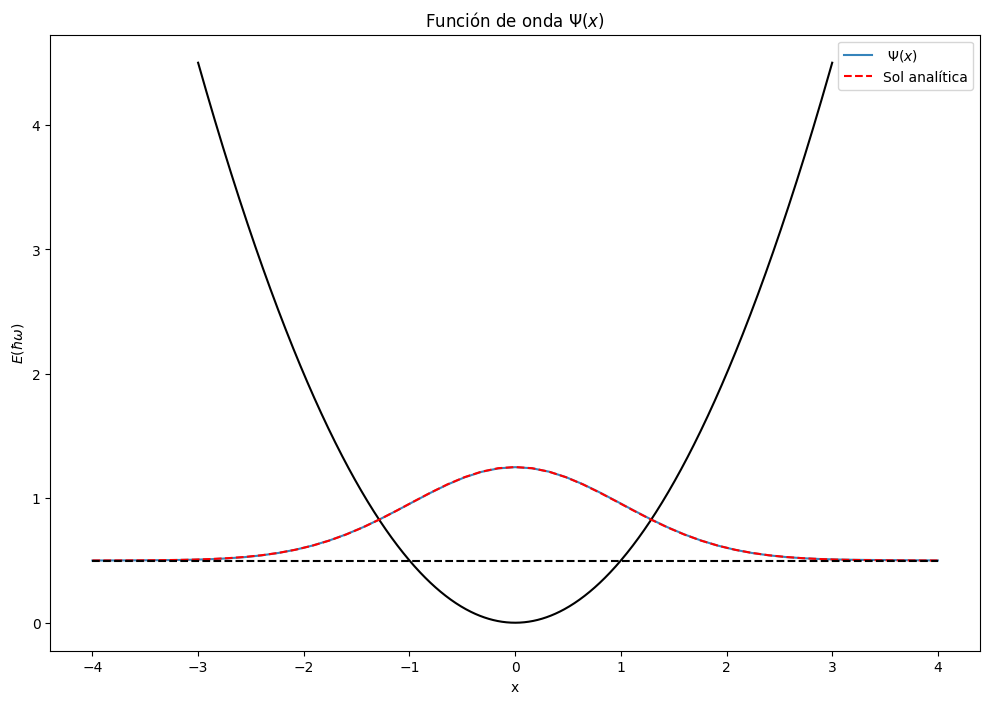

In [33]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 0.5+egparesultQHOground.data[-1, 0, :-1], '-', label=f' $\Psi(x)$', alpha=0.9)

plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(np.linspace(-4,4,n_variables), 0.5+APsi0, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E (\hbar \omega)$')
plt.legend();

In [34]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 10))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHOground.data.shape[1]*0.1)):
        plt.plot(X_grid, 0.5+egparesultQHOground.data[i,inds,:-1])#, label='Mejores soluciones')

    #plt.plot(X_grid, APsi0, 'k-', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(X_grid, 0.5+APsi0, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHOground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=144), Outp…

In [35]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHOground.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 0.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        0.5+ mean_prediction - 1.96 * std_prediction,
        0.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 0.5+1*APsi0, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHOground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=144), Outp…

In [36]:
Psi_ground=egparesultQHOground.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E0 = np.sqrt(-np.log(-egparesultQHOground.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así 
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground}

In [37]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid, max_iter=300, dead_iter=30, alpha=0.05, elite_factor=0.025, init_kernels=4,parallelize=True, init_data=(X_train, Y_train))
egparesultQHO1 = Gaussian.minimize(oneDHOExpE1, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [1.33955966]
IT:  1 	Best cost:  [1.33955966]
IT:  2 	Best cost:  [1.33955966]
IT:  3 	Best cost:  [1.33955966]
IT:  4 	Best cost:  [-1.34905888e-06]
IT:  5 	Best cost:  [-1.57700856e-06]
IT:  6 	Best cost:  [-1.94027461e-06]
IT:  7 	Best cost:  [-2.29963605e-06]
IT:  8 	Best cost:  [-2.78453393e-06]
IT:  9 	Best cost:  [-3.27379855e-06]
IT:  10 	Best cost:  [-3.92873234e-06]
IT:  11 	Best cost:  [-4.54391345e-06]
IT:  12 	Best cost:  [-5.15356391e-06]
IT:  13 	Best cost:  [-6.0769211e-06]
IT:  14 	Best cost:  [-7.1097952e-06]
IT:  15 	Best cost:  [-8.10734526e-06]
IT:  16 	Best cost:  [-9.42777659e-06]
IT:  17 	Best cost:  [-1.05242099e-05]
IT:  18 	Best cost:  [-1.1711253e-05]
IT:  19 	Best cost:  [-1.32145281e-05]
IT:  20 	Best cost:  [-1.44705754e-05]
IT:  21 	Best cost:  [-1.66290056e-05]
IT:  22 	Best cost:  [-1.81531654e-05]
IT:  23 	Best cost:  [-1.96185401e-05]
IT:  24 	Best cost:  [-2.10726813e-05]
IT:  25 	Best cost:  [-2.3487425e-05]
IT:  26 	Best cost: 

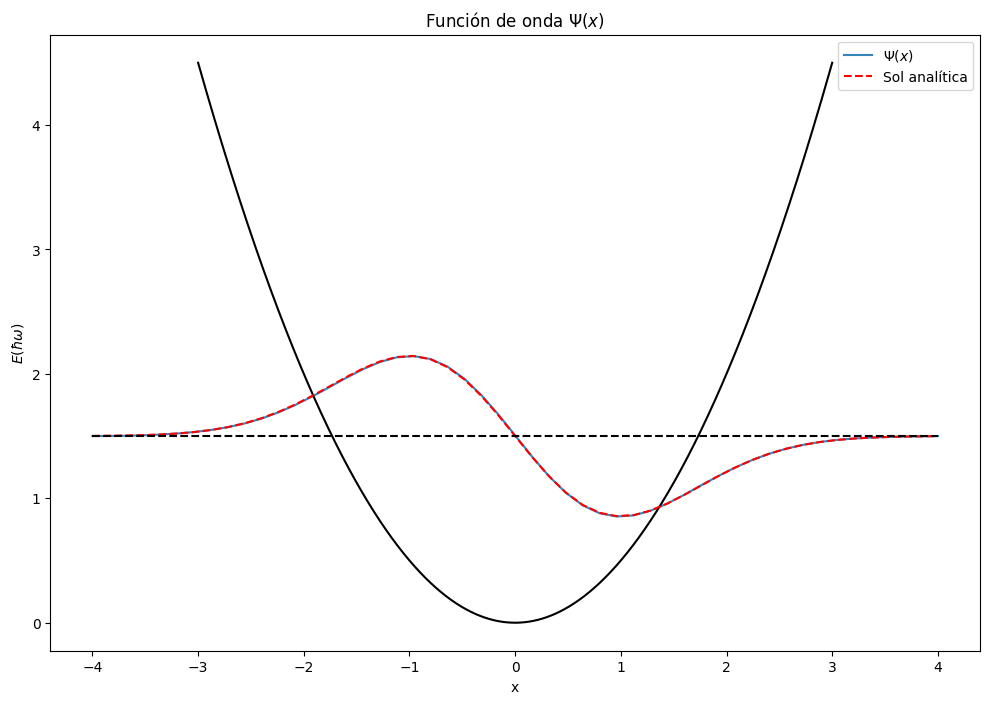

In [38]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 1.5+egparesultQHO1.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid, 1.5+-1*APsi1, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [39]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO1.data.shape[1])):
        plt.plot(X_grid, 1.5+egparesultQHO1.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 1.5+-1*APsi1, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=84), Outpu…

In [40]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO1.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 1.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        1.5+ mean_prediction - 1.96 * std_prediction,
        1.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 1.5+-1*APsi1, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=84), Outpu…

In [41]:
Psi1=egparesultQHO1.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E1 = np.sqrt(-np.log(-egparesultQHO1.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1}

In [42]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid, max_iter=300, dead_iter=50, alpha=0.05, elite_factor=0.025, init_kernels=4,parallelize=True, init_data=(X_train, Y_train))
egparesultQHO2 = Gaussian.minimize(oneDHOExpE2, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [2.58965569]
IT:  1 	Best cost:  [2.50223309]
IT:  2 	Best cost:  [2.22489766]
IT:  3 	Best cost:  [2.18459486]
IT:  4 	Best cost:  [-4.18333584e-10]
IT:  5 	Best cost:  [-5.16221438e-10]
IT:  6 	Best cost:  [-7.79999789e-10]
IT:  7 	Best cost:  [-1.06097188e-09]
IT:  8 	Best cost:  [-1.54393437e-09]
IT:  9 	Best cost:  [-2.25715501e-09]
IT:  10 	Best cost:  [-2.76414352e-09]
IT:  11 	Best cost:  [-4.31084337e-09]
IT:  12 	Best cost:  [-5.21936258e-09]
IT:  13 	Best cost:  [-7.96337239e-09]
IT:  14 	Best cost:  [-9.86361778e-09]
IT:  15 	Best cost:  [-1.36845547e-08]
IT:  16 	Best cost:  [-1.78941294e-08]
IT:  17 	Best cost:  [-2.37806065e-08]
IT:  18 	Best cost:  [-3.21320603e-08]
IT:  19 	Best cost:  [-4.46887412e-08]
IT:  20 	Best cost:  [-5.62249175e-08]
IT:  21 	Best cost:  [-7.1432916e-08]
IT:  22 	Best cost:  [-9.67748525e-08]
IT:  23 	Best cost:  [-1.26179167e-07]
IT:  24 	Best cost:  [-1.52878227e-07]
IT:  25 	Best cost:  [-1.93363905e-07]
IT:  26 	Best cos

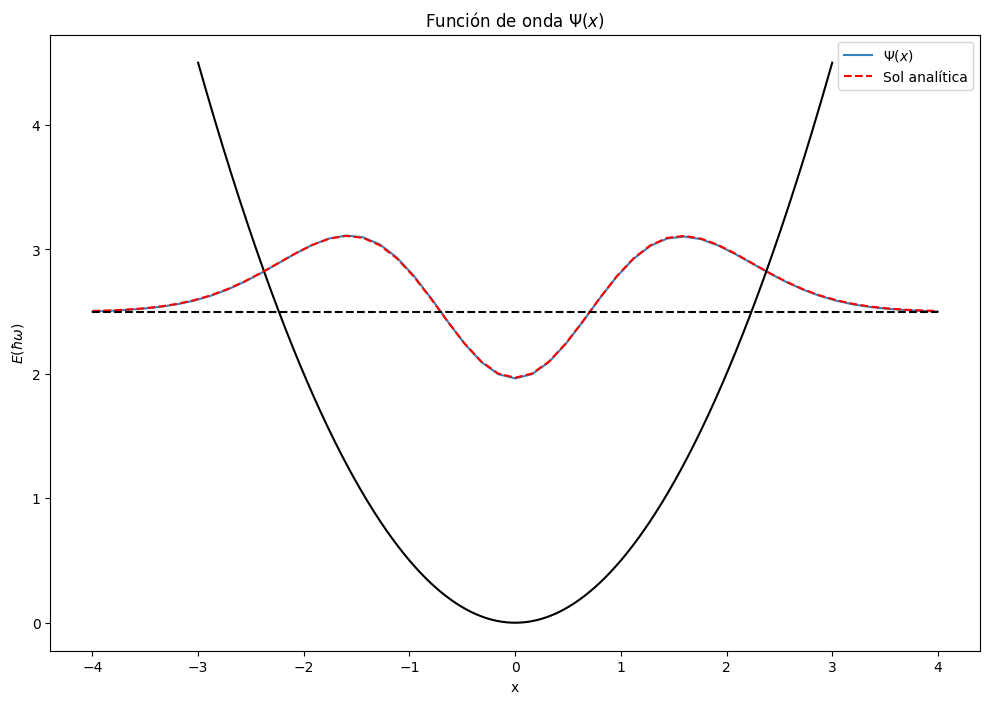

In [43]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 2.5+egparesultQHO2.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid, 2.5+APsi2, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [44]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO2.data.shape[1])):
        plt.plot(X_grid, 2.5+egparesultQHO2.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 2.5+APsi2, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=167), Outp…

In [45]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO2.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 2.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        2.5+ mean_prediction - 1.96 * std_prediction,
        2.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 2.5+1*APsi2, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=167), Outp…

In [46]:
Psi2=egparesultQHO2.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E2 = np.sqrt(-np.log(-egparesultQHO2.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2 }

In [47]:
Gaussian = EGPA(size_gen=800, grid_X=X_grid, max_iter=1000, dead_iter=120, alpha=0.2, elite_factor=0.08, init_kernels=8,parallelize=True, init_data=(X_train, Y_train))
egparesultQHO3 = Gaussian.minimize(oneDHOExpE3, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [3.2675518]
IT:  1 	Best cost:  [3.03190804]
IT:  2 	Best cost:  [2.94209132]
IT:  3 	Best cost:  [2.94209132]
IT:  4 	Best cost:  [-6.97297415e-14]
IT:  5 	Best cost:  [-6.97297415e-14]
IT:  6 	Best cost:  [-6.97297415e-14]
IT:  7 	Best cost:  [-8.94535461e-14]
IT:  8 	Best cost:  [-1.15118637e-13]
IT:  9 	Best cost:  [-1.62022528e-13]
IT:  10 	Best cost:  [-2.19439765e-13]
IT:  11 	Best cost:  [-2.56106554e-13]
IT:  12 	Best cost:  [-3.87327918e-13]
IT:  13 	Best cost:  [-4.92658437e-13]
IT:  14 	Best cost:  [-6.06577389e-13]
IT:  15 	Best cost:  [-8.60229211e-13]
IT:  16 	Best cost:  [-1.14380788e-12]
IT:  17 	Best cost:  [-1.56746489e-12]
IT:  18 	Best cost:  [-1.8726822e-12]
IT:  19 	Best cost:  [-2.4530737e-12]
IT:  20 	Best cost:  [-2.98762278e-12]
IT:  21 	Best cost:  [-3.83907655e-12]
IT:  22 	Best cost:  [-6.38784627e-12]
IT:  23 	Best cost:  [-7.07788139e-12]
IT:  24 	Best cost:  [-8.51192419e-12]
IT:  25 	Best cost:  [-1.14421035e-11]
IT:  26 	Best cost:

Exception ignored in: <function _releaseLock at 0x7f01aa427880>
Traceback (most recent call last):
  File "/home/dani/anaconda3/envs/EDAspy/lib/python3.12/logging/__init__.py", line 243, in _releaseLock
    def _releaseLock():
    
KeyboardInterrupt: 


IT:  70 	Best cost:  [-1.9400758e-07]
IT:  71 	Best cost:  [-2.30143416e-07]
IT:  72 	Best cost:  [-2.77856362e-07]
IT:  73 	Best cost:  [-3.02470068e-07]
IT:  74 	Best cost:  [-3.94172491e-07]
IT:  75 	Best cost:  [-4.08013832e-07]
IT:  76 	Best cost:  [-4.96724008e-07]
IT:  77 	Best cost:  [-5.64465282e-07]
IT:  78 	Best cost:  [-6.96693621e-07]
IT:  79 	Best cost:  [-7.59595815e-07]
IT:  80 	Best cost:  [-8.99365205e-07]
IT:  81 	Best cost:  [-9.78945084e-07]
IT:  82 	Best cost:  [-1.2195827e-06]
IT:  83 	Best cost:  [-1.41457661e-06]
IT:  84 	Best cost:  [-1.5267181e-06]
IT:  85 	Best cost:  [-1.81926081e-06]
IT:  86 	Best cost:  [-2.10305701e-06]
IT:  87 	Best cost:  [-2.35247154e-06]
IT:  88 	Best cost:  [-2.59532019e-06]
IT:  89 	Best cost:  [-2.89510553e-06]
IT:  90 	Best cost:  [-3.56243661e-06]
IT:  91 	Best cost:  [-3.71624517e-06]
IT:  92 	Best cost:  [-4.17346815e-06]
IT:  93 	Best cost:  [-4.72443904e-06]
IT:  94 	Best cost:  [-5.10959834e-06]
IT:  95 	Best cost:  [-5.628

KeyboardInterrupt: 

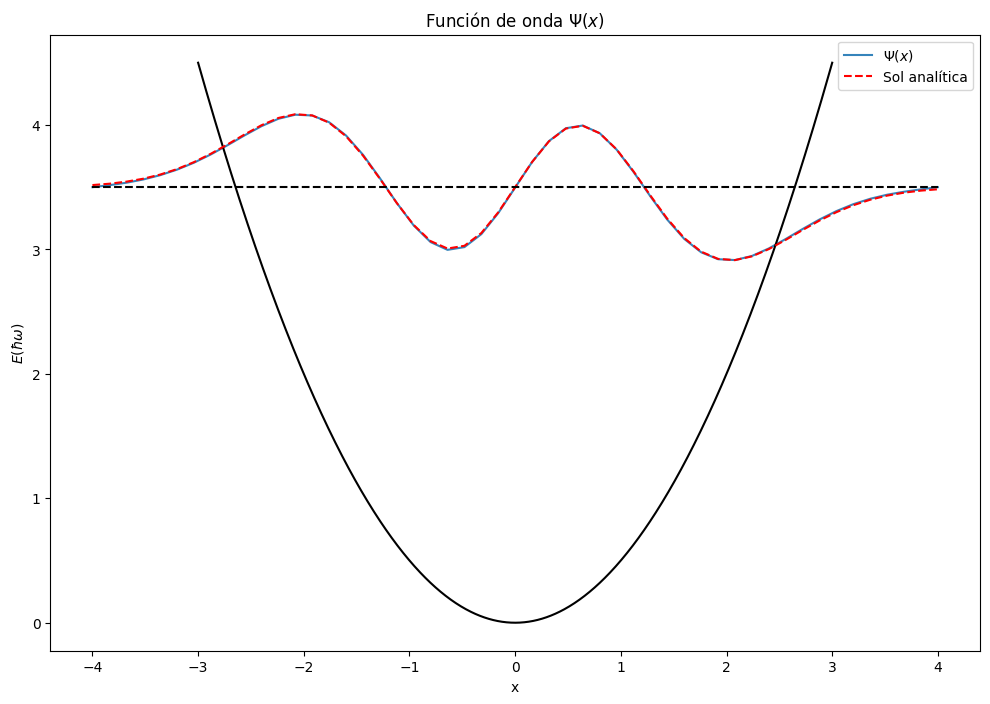

In [21]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 3.5+egparesultQHO3.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid, 3.5+-1*APsi3, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [32]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO3.data.shape[1])):
        plt.plot(X_grid, 3.5+egparesultQHO3.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 3.5+-1*APsi3, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=440), Outp…

In [29]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO3.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 3.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        3.5+ mean_prediction - 1.96 * std_prediction,
        3.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 3.5+-1*APsi3, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);



# mean_prediction, std_prediction = egparesultQHO3.GP_hist[0].predict(X_grid, return_std=True)
# #plt.scatter(X_train, Y_train, label="Observations")
# plt.plot(X_grid, mean_prediction, label="Mean prediction")
# plt.fill_between(
#     X_grid.ravel(),
#     mean_prediction - 1.96 * std_prediction,
#     mean_prediction + 1.96 * std_prediction,
#     alpha=0.5,
#     label=r"95% confidence interval",
# )
# plt.legend()
# plt.xlabel("$x$")
# plt.ylabel("$f(x)$")
# _ = plt.title("Gaussian process regression on noise-free dataset")

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=440), Outp…

<Figure size 640x480 with 0 Axes>

<Figure size 2000x1200 with 0 Axes>

In [23]:
egparesultQHOground.means

[array([0.00000000e+00, 2.07263510e-04, 5.88839824e-04, 1.27841917e-03,
        2.45122259e-03, 4.34523609e-03, 7.29299274e-03, 1.17598042e-02,
        1.83803611e-02, 2.79818190e-02, 4.15795934e-02, 6.03329324e-02,
        8.54515376e-02, 1.18052405e-01, 1.58976139e-01, 2.08583139e-01,
        2.66559452e-01, 3.31767553e-01, 4.02176591e-01, 4.74899180e-01,
        5.46347735e-01, 6.12504822e-01, 6.69282150e-01, 7.12925634e-01,
        7.40412794e-01, 7.49786353e-01, 7.40375217e-01, 7.12870012e-01,
        6.69242098e-01, 6.12518663e-01, 5.46447955e-01, 4.75103548e-01,
        4.02483154e-01, 3.32154417e-01, 2.66988989e-01, 2.09009252e-01,
        1.59352772e-01, 1.18341687e-01, 8.56305366e-02, 6.03984048e-02,
        4.15504688e-02, 2.78990787e-02, 1.83037369e-02, 1.17603978e-02,
        7.44108272e-03, 4.69308138e-03, 3.01172074e-03, 2.00184789e-03,
        1.34108912e-03, 7.53870647e-04, 0.00000000e+00]),
 array([0.00000000e+00, 2.07263510e-04, 5.88839824e-04, 1.27841917e-03,
      

In [31]:
egparesultQHO3.std[-1]

array([0.  , 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.  ])

In [25]:
egparesultQHOground.GP_hist[-1].kernel_.__call__([6, 6.1])

array([[0.08738598, 0.08738598],
       [0.08738598, 0.08738598]])

In [26]:
egparesultQHOground.GP_hist[-1].kernel_

0.296**2 * RBF(length_scale=1.41)

In [27]:
0.281**2*np.exp(0.1**2/(2*1.38**2))

np.float64(0.07916858440134154)

In [28]:
egparesultQHOground.GP_hist[-1].kernel_.diag(X_grid)

array([0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598, 0.08738598, 0.08738598, 0.08738598, 0.08738598,
       0.08738598])